#### Automated Data Cleaning 


#### Types of Data
#### 1.Missing Completely At Random(MCAR)
#### 2.Missing At Random(MAR)
#### 3.Missing Not At Random(MNAR)

In [1]:
import pandas as pd 
df=pd.read_csv('unclean_smartwatch_health_data.csv')
df

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,1860.0,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,2294.0,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,2130.0,61.950165,98.583797,15679.067648,NaN,Highly_Active,6
...,...,...,...,...,...,...,...
9995,1524.0,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,4879.0,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,2624.0,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,4907.0,NaN,98.401058,3364.788855,5.691233932149209,Active,8


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   User ID                 9799 non-null   float64
 1   Heart Rate (BPM)        9600 non-null   float64
 2   Blood Oxygen Level (%)  9700 non-null   float64
 3   Step Count              9900 non-null   float64
 4   Sleep Duration (hours)  9850 non-null   str    
 5   Activity Level          9800 non-null   str    
 6   Stress Level            9800 non-null   str    
dtypes: float64(4), str(3)
memory usage: 547.0 KB


#### The missing values are more than 5% so removing them may not be viable so try to fill them 

In [3]:
df=df[['Heart Rate (BPM)','Blood Oxygen Level (%)','Step Count','Sleep Duration (hours)','Activity Level','Stress Level']]

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        9600 non-null   float64
 1   Blood Oxygen Level (%)  9700 non-null   float64
 2   Step Count              9900 non-null   float64
 3   Sleep Duration (hours)  9850 non-null   str    
 4   Activity Level          9800 non-null   str    
 5   Stress Level            9800 non-null   str    
dtypes: float64(3), str(3)
memory usage: 468.9 KB


In [5]:
df

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,61.950165,98.583797,15679.067648,NaN,Highly_Active,6
...,...,...,...,...,...,...
9995,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,NaN,98.401058,3364.788855,5.691233932149209,Active,8


In [6]:
df[df['Heart Rate (BPM)'].isna()]

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
1,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
17,NaN,96.052853,3488.919508,6.718661172525927,Seddentary,4
75,NaN,100.000000,3124.118038,4.229887888280923,Actve,1
105,NaN,98.276558,3039.112276,5.209658021888749,NaN,6
158,NaN,99.478461,11559.663606,6.470651489160172,Highly_Active,7
...,...,...,...,...,...,...
9875,NaN,99.842527,4454.770218,5.520745925308887,Sedentary,3
9956,NaN,100.000000,3584.236177,6.659533807452561,Highly_Active,5
9971,NaN,99.319841,26.215769,6.367659085134144,Active,10
9990,NaN,100.000000,3817.269018,8.595259517189332,Seddentary,2


In [7]:
df['Heart Rate (BPM)'].describe()
## which represents outliers look at max = 296 of heartbeat.so,use median

count    9600.000000
mean       76.035462
std        19.412483
min        40.000000
25%        64.890152
50%        75.220601
75%        85.198249
max       296.593970
Name: Heart Rate (BPM), dtype: float64

In [8]:
df['Heart Rate (BPM)']=df['Heart Rate (BPM)'].fillna(df['Heart Rate (BPM)'].median())

In [9]:
df['Heart Rate (BPM)'].isnull().sum()

np.int64(0)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        10000 non-null  float64
 1   Blood Oxygen Level (%)  9700 non-null   float64
 2   Step Count              9900 non-null   float64
 3   Sleep Duration (hours)  9850 non-null   str    
 4   Activity Level          9800 non-null   str    
 5   Stress Level            9800 non-null   str    
dtypes: float64(3), str(3)
memory usage: 468.9 KB


In [11]:
df['Blood Oxygen Level (%)'].describe()

count    9700.000000
mean       97.841581
std         1.732863
min        90.791208
25%        96.662683
50%        98.010642
75%        99.376179
max       100.000000
Name: Blood Oxygen Level (%), dtype: float64

In [12]:
df['Blood Oxygen Level (%)']=df['Blood Oxygen Level (%)'].fillna(df['Blood Oxygen Level (%)'].mean())

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        10000 non-null  float64
 1   Blood Oxygen Level (%)  10000 non-null  float64
 2   Step Count              9900 non-null   float64
 3   Sleep Duration (hours)  9850 non-null   str    
 4   Activity Level          9800 non-null   str    
 5   Stress Level            9800 non-null   str    
dtypes: float64(3), str(3)
memory usage: 468.9 KB


In [14]:
df['Step Count'].value_counts()

Step Count
5450.390578     1
727.601610      1
2826.521994     1
13797.338044    1
15679.067648    1
               ..
2948.491953     1
4725.623070     1
2571.492060     1
3364.788855     1
544.696104      1
Name: count, Length: 9900, dtype: int64

#### The step count is a time bound parameter and varies with time.so,it can be categorized as Time Series Data
#### we use forward fill and backward fill

In [15]:
df['Step Count'] = df['Step Count'].ffill()

In [16]:
df

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,75.220601,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,61.950165,98.583797,15679.067648,NaN,Highly_Active,6
...,...,...,...,...,...,...
9995,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,75.220601,98.401058,3364.788855,5.691233932149209,Active,8


In [17]:
df['Sleep Duration (hours)'] = pd.to_numeric(df['Sleep Duration (hours)'], errors='coerce')
df['Sleep Duration (hours)']=df['Sleep Duration (hours)'].fillna(df['Sleep Duration (hours)'].median())

In [18]:
df['Activity Level']=df['Activity Level'].fillna(df['Activity Level'].mode()[0])

In [19]:
df['Activity Level'].isnull().sum()

np.int64(0)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        10000 non-null  float64
 1   Blood Oxygen Level (%)  10000 non-null  float64
 2   Step Count              10000 non-null  float64
 3   Sleep Duration (hours)  10000 non-null  float64
 4   Activity Level          10000 non-null  str    
 5   Stress Level            9800 non-null   str    
dtypes: float64(4), str(2)
memory usage: 468.9 KB


#### Stress level column contains only one str value that is high stress but it contains some significance--> so we use 
#### constant imputation 

In [21]:
df['Stress Level'].value_counts()

Stress Level
2            1007
7            1006
6            1001
3             995
1             984
9             976
4             966
10            954
5             945
8             917
Very High      49
Name: count, dtype: int64

In [22]:
df['Stress Level']=df['Stress Level'].fillna(5)

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        10000 non-null  float64
 1   Blood Oxygen Level (%)  10000 non-null  float64
 2   Step Count              10000 non-null  float64
 3   Sleep Duration (hours)  10000 non-null  float64
 4   Activity Level          10000 non-null  str    
 5   Stress Level            10000 non-null  object 
dtypes: float64(4), object(1), str(1)
memory usage: 468.9+ KB


In [24]:
%pip uninstall sklearn -y
%pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import sklearn
print(sklearn.__version__)

1.9.1


In [26]:
from sklearn.impute import SimpleImputer

In [27]:
df=pd.read_csv('unclean_smartwatch_health_data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   User ID                 9799 non-null   float64
 1   Heart Rate (BPM)        9600 non-null   float64
 2   Blood Oxygen Level (%)  9700 non-null   float64
 3   Step Count              9900 non-null   float64
 4   Sleep Duration (hours)  9850 non-null   str    
 5   Activity Level          9800 non-null   str    
 6   Stress Level            9800 non-null   str    
dtypes: float64(4), str(3)
memory usage: 547.0 KB


In [28]:
df=df.drop(columns=['User ID'])
df

,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,61.950165,98.583797,15679.067648,NaN,Highly_Active,6
...,...,...,...,...,...,...
9995,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,NaN,98.401058,3364.788855,5.691233932149209,Active,8


In [29]:
imputer=SimpleImputer(strategy='median')
df['Heart Rate (BPM)']=imputer.fit_transform(df[['Heart Rate (BPM)']]).ravel()

In [30]:
imputer=SimpleImputer(strategy='mean')
df['Blood Oxygen Level (%)']=imputer.fit_transform(df[['Blood Oxygen Level (%)']]).ravel()

In [31]:
imputer = SimpleImputer(strategy='median')
df['Step Count'] = imputer.fit_transform(df[['Step Count']]).ravel()

In [32]:
df['Sleep Duration (hours)'] = pd.to_numeric(df['Sleep Duration (hours)'], errors='coerce')
imputer = SimpleImputer(strategy='median')
df['Sleep Duration (hours)'] = imputer.fit_transform(df[['Sleep Duration (hours)']]).ravel()

In [33]:
imputer = SimpleImputer(strategy='most_frequent')
df['Activity Level'] = imputer.fit_transform(df[['Activity Level']]).ravel()

In [34]:
imputer = SimpleImputer(strategy='constant',fill_value=5)
df['Stress Level'] = imputer.fit_transform(df[['Stress Level']]).ravel()

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Heart Rate (BPM)        10000 non-null  float64
 1   Blood Oxygen Level (%)  10000 non-null  float64
 2   Step Count              10000 non-null  float64
 3   Sleep Duration (hours)  10000 non-null  float64
 4   Activity Level          10000 non-null  str    
 5   Stress Level            10000 non-null  object 
dtypes: float64(4), object(1), str(1)
memory usage: 468.9+ KB


In [36]:
from sklearn.datasets import load_iris

In [37]:
df=load_iris()

In [38]:
df

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

Attributes:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
class                    str
dtype: object
Records: 150
Class counts:
 class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


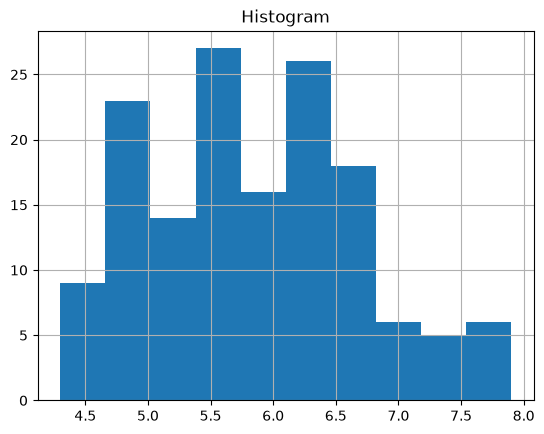

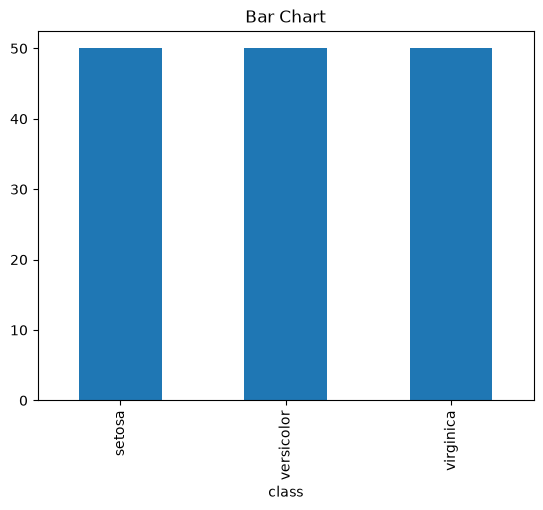

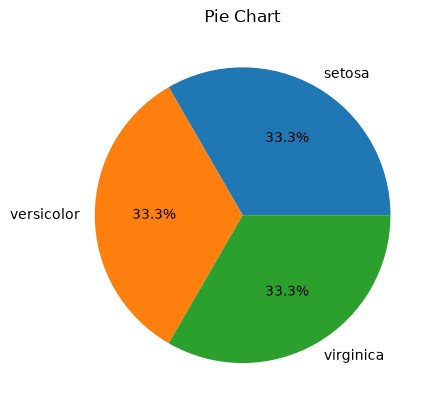

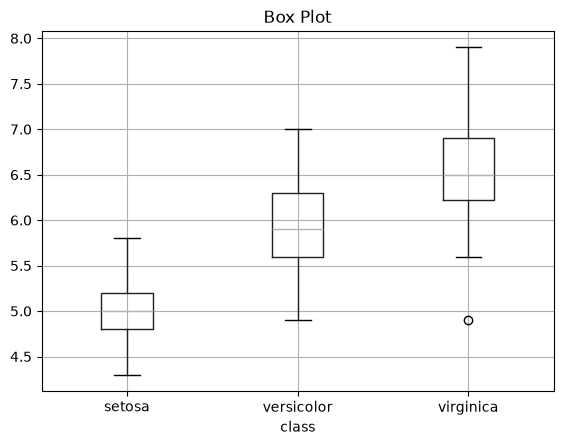

In [43]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["class"] = [iris.target_names[i] for i in iris.target]

print("Attributes:\n", df.dtypes)
print("Records:", len(df))
print("Class counts:\n", df["class"].value_counts())

# Histogram
df["sepal length (cm)"].hist()
plt.title("Histogram")
plt.show()

# Bar chart
df["class"].value_counts().plot(kind="bar")
plt.title("Bar Chart")
plt.show()

# Pie chart
df["class"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Pie Chart")
plt.ylabel("")
plt.show()

# Box plot
df.boxplot(column="sepal length (cm)", by="class")
plt.suptitle("")
plt.title("Box Plot")
plt.show()
